INSTALL PACKAGES FOR GRAPH DATA PRECOMPUTATION

PLEASE USE CPU RUNTIME WITH MORE CPU CORES FOR THIS SECTION, TPU MAY BE USED, HAS MORE CORES THAN CPU OFFERED IN COLAB HERE

In [ ]:
#### EVEN THOUGH DGL HAS CUDA VERSIONS BUT THEN THE PYTHON CUDA VRESION AVAIALBLE NOW ARE OLD AND WONT WORK IN THE CURRENT GOOGLE COLAB WITH PRE-INSTALLED CURRENT OR UP-TO-DATE CUDA DRIVERS
#### THAT IS WHY I USED TPU RUNTIME WHICH IS FAST ENOUGH FOR ALL GRAPH DATA PRE-COMPUTATIONS IN THIS WORK

In [ ]:
# MOUNT GOOGLE DRIVE
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install torch==2.4.0
!pip install torch_geometric
!pip install  dgl -f https://data.dgl.ai/wheels/torch-2.4/repo.html
!pip install numpy==1.24.4
!pip install rdkit
!pip install graphein[extras]

Looking in links: https://data.dgl.ai/wheels/torch-2.4/repo.html
  Using cached numpy-1.24.4.tar.gz (10.9 MB)
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.


IMPORT LIBRARIES AMD FUNCTIONS

In [ ]:
import os
import sys
import torch
import rdkit
import torch
import logging
import numpy as np
import pandas as pd
import networkx as nx
from tqdm import tqdm
import graphein.molecule as gm
from rdkit import RDLogger
from sklearn.model_selection import train_test_split
from torch_geometric.data import Data
from ablate.graph_generator_ablate import run_graph_generator  # make sure ablate folder is present in the current woring directory

In [ ]:
#### NOTE ######

### PLEASE MAKE SURE ALL RELEVENT FILES ARE SAVED TO GOOGLE DRIVE FOLDER SO YOU DONT LOOSE THEM AFTER RUNTIME DISCONNECTS.

## DOWNLOAD QM9 DATASET, CONSTRUCT GRAPHS AND PE, AND ADD LABELS ##

LOAD QM9 DATASET FROM DRIVE

In [ ]:
qm = pd.read_csv("/content/drive/MyDrive/thesis/others/qm9.csv")
qm

,mol_id,smiles,A,B,C,mu,alpha,homo,lumo,gap,...,zpve,u0,u298,h298,g298,cv,u0_atom,u298_atom,h298_atom,g298_atom
0,gdb_1,C,157.71180,157.709970,157.706990,0.0000,13.21,-0.3877,0.1171,0.5048,...,0.044749,-40.478930,-40.476062,-40.475117,-40.498597,6.469,-395.999595,-398.643290,-401.014647,-372.471772
1,gdb_2,N,293.60975,293.541110,191.393970,1.6256,9.46,-0.2570,0.0829,0.3399,...,0.034358,-56.525887,-56.523026,-56.522082,-56.544961,6.316,-276.861363,-278.620271,-280.399259,-259.338802
2,gdb_3,O,799.58812,437.903860,282.945450,1.8511,6.31,-0.2928,0.0687,0.3615,...,0.021375,-76.404702,-76.401867,-76.400922,-76.422349,6.002,-213.087624,-213.974294,-215.159658,-201.407171
3,gdb_4,C#C,0.00000,35.610036,35.610036,0.0000,16.28,-0.2845,0.0506,0.3351,...,0.026841,-77.308427,-77.305527,-77.304583,-77.327429,8.574,-385.501997,-387.237686,-389.016047,-365.800724
4,gdb_5,C#N,0.00000,44.593883,44.593883,2.8937,12.99,-0.3604,0.0191,0.3796,...,0.016601,-93.411888,-93.409370,-93.408425,-93.431246,6.278,-301.820534,-302.906752,-304.091489,-288.720028
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
133880,gdb_133881,C1C2C3C4C5OC14C5N23,3.59483,2.198990,1.904230,1.6637,69.37,-0.2254,0.0588,0.2842,...,0.127406,-400.633868,-400.628599,-400.627654,-400.663098,23.658,-1603.983913,-1614.898804,-1623.788097,-1492.819438
133881,gdb_133882,C1N2C3C2C2C4OC12C34,3.65648,2.142370,1.904390,1.2976,69.52,-0.2393,0.0608,0.3002,...,0.127495,-400.629713,-400.624444,-400.623500,-400.658942,23.697,-1601.376613,-1612.291504,-1621.181424,-1490.211511
133882,gdb_133883,C1N2C3C4C5C2C13CN45,3.67118,2.143140,1.895010,1.2480,73.60,-0.2233,0.0720,0.2953,...,0.140458,-380.753918,-380.748619,-380.747675,-380.783148,23.972,-1667.045429,-1678.830048,-1688.312964,-1549.143391
133883,gdb_133884,C1N2C3C4C5CC13C2C45,3.52845,2.151310,1.865820,1.9576,77.40,-0.2122,0.0881,0.3003,...,0.152222,-364.720374,-364.714974,-364.714030,-364.749650,24.796,-1794.600439,-1807.210860,-1817.286772,-1670.349892


In [ ]:
len(qm)

133885

In [ ]:
# ABLATION WILL ONLY BE PERFORMED FOR zero point vibrational energy (ZPVE) PREDICTION

qm_zpve = qm[["smiles", "zpve"]]
qm_zpve

,smiles,zpve
0,C,0.044749
1,N,0.034358
2,O,0.021375
3,C#C,0.026841
4,C#N,0.016601
...,...,...
133880,C1C2C3C4C5OC14C5N23,0.127406
133881,C1N2C3C2C2C4OC12C34,0.127495
133882,C1N2C3C4C5C2C13CN45,0.140458
133883,C1N2C3C4C5CC13C2C45,0.152222


In [ ]:
# randomly split this into 85:15 train:validation sets

train_idx, valid_idx = train_test_split(range(len(qm_zpve)), test_size=0.15, random_state=42)

In [ ]:
print(len(train_idx))
print(len(valid_idx))

113802
20083


In [ ]:
train_dataset = qm_zpve.iloc[train_idx]
valid_dataset = qm_zpve.iloc[valid_idx]

In [ ]:
train_dataset

,smiles,zpve
7129,C(CO)C(=O)CC=O,0.126724
51834,N=COC1CNCC1=O,0.136327
16525,OC12CCN3CC1C23,0.144414
8110,CC1C2N(C)CC12O,0.163979
46942,O=C1CNC2CC3C2N13,0.139090
...,...,...
110268,OCC1C2C(O)C1C2O,0.158082
119879,COCC1=CCCC1O,0.181846
103694,CC1(CO)CC1(O)C#N,0.144763
131932,c1c(coc1N)N(=O)=O,0.089436


In [ ]:
valid_dataset

,smiles,zpve
3115,N#CC12CC1CO2,0.090625
117879,COCC(O)C#CC=O,0.131823
23433,COC1C2CC(=NO)C12,0.146098
61955,CC(CC=O)OCC#C,0.154138
98811,COC(=N)N1CCC1=N,0.147974
...,...,...
20507,CC#Cc1ccon1,0.095322
32909,CCCc1cnc([nH]1)O,0.160305
3614,C1C2C3CCC1C23,0.152095
76573,CC1C(O)C11CCCC1,0.206396


Identify minimum and maximum nodes in all datasets

In [ ]:
# TRAINING DATASET

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)
RDLogger.DisableLog('rdApp.*')

config = gm.MoleculeGraphConfig()

num_nodes_list = []
error_indices = []

for i, smile in tqdm(enumerate(train_dataset['smiles']), total=len(train_dataset['smiles']), desc="Computing graphs and collecting node counts in training dataset"):
    try:
        graph = gm.construct_graph(smiles=smile, config=config)
        num_nodes = graph.number_of_nodes()
        num_nodes_list.append(num_nodes)
    except Exception as e:
        logger.error(f"Error at index {i}")
        error_indices.append(i)
        continue

min_nodes = min(num_nodes_list)
max_nodes = max(num_nodes_list)


Computing graphs and collecting node counts in training dataset: 100%|██████████| 113802/113802 [00:42<00:00, 2701.41it/s]


In [ ]:
print(f"Maximum number of nodes in training dataset: {max_nodes}")
print(f"Minimum number of nodes in training dataset: {min_nodes}")
print(f"Number of molecule indices in training dataset with errors: {len(error_indices)}")

Maximum number of nodes in training dataset: 9
Minimum number of nodes in training dataset: 1
Number of molecule indices in training dataset with errors: 0


In [ ]:
# filtered failed molecules out, none failed though

train_dataset_ = train_dataset.drop(train_dataset.index[error_indices]).reset_index(drop=True)
train_dataset_

,smiles,zpve
0,C(CO)C(=O)CC=O,0.126724
1,N=COC1CNCC1=O,0.136327
2,OC12CCN3CC1C23,0.144414
3,CC1C2N(C)CC12O,0.163979
4,O=C1CNC2CC3C2N13,0.139090
...,...,...
113797,OCC1C2C(O)C1C2O,0.158082
113798,COCC1=CCCC1O,0.181846
113799,CC1(CO)CC1(O)C#N,0.144763
113800,c1c(coc1N)N(=O)=O,0.089436


In [ ]:
# VALIDATION DATASET

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)
RDLogger.DisableLog('rdApp.*')

config = gm.MoleculeGraphConfig()

num_nodes_list = []
error_indices = []

for i, smile in tqdm(enumerate(valid_dataset['smiles']), total=len(valid_dataset['smiles']), desc="Computing graphs and collecting node counts in validation dataset"):
    try:
        graph = gm.construct_graph(smiles=smile, config=config)
        num_nodes = graph.number_of_nodes()
        num_nodes_list.append(num_nodes)
    except Exception as e:
        logger.error(f"Error at index {i}")
        error_indices.append(i)
        continue

min_nodes = min(num_nodes_list)
max_nodes = max(num_nodes_list)


Computing graphs and collecting node counts in validation dataset: 100%|██████████| 20083/20083 [00:07<00:00, 2729.58it/s]


In [ ]:
print(f"Maximum number of nodes in validation dataset: {max_nodes}")
print(f"Minimum number of nodes in validation dataset: {min_nodes}")
print(f" Number of molecule indices in validation dataset with errors: {error_indices}")

Maximum number of nodes in validation dataset: 9
Minimum number of nodes in validation dataset: 1
 Number of molecule indices in validation dataset with errors: []


In [ ]:
# All validation samples succesfully converted to graphs, nothing to be removed

In [ ]:
train_dataset_.to_csv('/content/drive/MyDrive/thesis/others/TRAIN_DATASET_ABLATION.csv', index=False)
valid_dataset.to_csv('/content/drive/MyDrive/thesis/others/VALIDATION_DATASET_ABLATION.csv', index=False)

In [ ]:
# NOW THE MAXIMUM NODE IN THE ENTIRE SPLITS IS 9, WE WILL CLIP THE DIMENSION OF THE PE VECTOR TO 9 (9 ATOMS) TO AVOID MANY PADS

In [ ]:
train_dataset_ = pd.read_csv('/content/drive/MyDrive/thesis/others/TRAIN_DATASET_ABLATION.csv')
valid_dataset = pd.read_csv('/content/drive/MyDrive/thesis/others/VALIDATION_DATASET_ABLATION.csv')

In [ ]:
train_dataset_

,smiles,zpve
0,C(CO)C(=O)CC=O,0.126724
1,N=COC1CNCC1=O,0.136327
2,OC12CCN3CC1C23,0.144414
3,CC1C2N(C)CC12O,0.163979
4,O=C1CNC2CC3C2N13,0.139090
...,...,...
113797,OCC1C2C(O)C1C2O,0.158082
113798,COCC1=CCCC1O,0.181846
113799,CC1(CO)CC1(O)C#N,0.144763
113800,c1c(coc1N)N(=O)=O,0.089436


In [ ]:
valid_dataset

,smiles,zpve
0,N#CC12CC1CO2,0.090625
1,COCC(O)C#CC=O,0.131823
2,COC1C2CC(=NO)C12,0.146098
3,CC(CC=O)OCC#C,0.154138
4,COC(=N)N1CCC1=N,0.147974
...,...,...
20078,CC#Cc1ccon1,0.095322
20079,CCCc1cnc([nH]1)O,0.160305
20080,C1C2C3CCC1C23,0.152095
20081,CC1C(O)C11CCCC1,0.206396


In [ ]:
train_labels = train_dataset_["zpve"]
valid_labels = valid_dataset["zpve"]

In [ ]:
train_labels

,zpve
0,0.126724
1,0.136327
2,0.144414
3,0.163979
4,0.139090
...,...
113797,0.158082
113798,0.181846
113799,0.144763
113800,0.089436


In [ ]:
valid_labels

,zpve
0,0.090625
1,0.131823
2,0.146098
3,0.154138
4,0.147974
...,...
20078,0.095322
20079,0.160305
20080,0.152095
20081,0.206396


In [ ]:
train_labels = torch.tensor(train_labels.values, dtype=torch.float)
valid_labels = torch.tensor(valid_labels.values, dtype=torch.float)

COMPUTE GRAPH DATA

In [ ]:
# NOTE: run_graph_generator returns tensor of pickle object containing node features, edge indices, edge attributes and graph Laplacian positional encodings (PE) for each node in a graph.
# PE dimension capped at 9 atoms, thus k=9 for ablation experiments with qm9 dataset

# smiles_list = Pandas Series of SMILES or list of SMILES with one SMILES per row
# run_graph_generator = Core function does performs the end-to-end computation

In [ ]:
if __name__ == "__main__":

  smiles_list = train_dataset_["smiles"]

  node_features_tensor, edge_features_tensor, edges_indices, laplacian_pos = run_graph_generator(smiles_list)

  all_graph_data = {
        'node_features': node_features_tensor,
        'edge_features': edge_features_tensor,
        'edge_indices': edges_indices,
        'laplacian_pos': laplacian_pos
  }

  save_dir = "/content"
  os.makedirs(save_dir, exist_ok=True)
  filepath = os.path.join(save_dir, "All_graph_data_training.pkl")

  try:
      torch.save(all_graph_data, filepath)
  except Exception as e:
      print(f"Error saving molecular graph data: {e}")

In [ ]:
# Load and inspect

tr = torch.load("/content/All_graph_data_training.pkl", weights_only=False)

# then extract all content
node_features_t = tr['node_features']
edge_features_t = tr['edge_features']
edge_indices_t = tr['edge_indices']
laplacian_pos_t = tr['laplacian_pos']

In [ ]:
print(len(node_features_t))
print(len(edge_features_t))
print(len(edge_indices_t))
print(len(laplacian_pos_t))

113802
113802
113802
113802


In [ ]:
node_features_t[0]

tensor([[ 1.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000, 12.0110,  2.0000,  4.0000,  4.0000,  2.0000,
          2.0000,  0.0000,  2.0000,  2.0000,  0.0000,  0.0000,  4.0000,  0.0000,
          0.0000,  1.0000,  0.0000,  0.0000,  0.0000],
        [ 1.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000, 12.0110,  2.0000,  4.0000,  4.0000,  2.0000,
          2.0000,  0.0000,  2.0000,  2.0000,  0.0000,  0.0000,  4.0000,  0.0000,
          0.0000,  1.0000,  0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  1.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000, 15.9990,  1.0000,  2.0000,  2.0000,  1.0000,
          1.0000,  0.0000,  1.0000,  1.0000,  0.0000,  0.0000,  4.0000,  0.0000,
          0.0000,  1.0000,  0.0000,  0.0000,  0.0000],
        [ 1.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000

In [ ]:
edge_features_t[0]

tensor([[2., 0., 0., 0., 0., 0., 0.],
        [2., 0., 0., 0., 0., 0., 0.],
        [2., 0., 0., 0., 0., 0., 0.],
        [3., 0., 0., 0., 0., 0., 0.],
        [2., 0., 0., 0., 0., 0., 0.],
        [2., 0., 0., 0., 0., 0., 0.],
        [3., 0., 0., 0., 0., 0., 0.],
        [2., 0., 0., 0., 0., 0., 0.],
        [2., 0., 0., 0., 0., 0., 0.],
        [2., 0., 0., 0., 0., 0., 0.],
        [3., 0., 0., 0., 0., 0., 0.],
        [2., 0., 0., 0., 0., 0., 0.],
        [2., 0., 0., 0., 0., 0., 0.],
        [3., 0., 0., 0., 0., 0., 0.]])

In [ ]:
edge_indices_t[0]

[(0, 1),
 (0, 3),
 (1, 2),
 (3, 4),
 (3, 5),
 (5, 6),
 (6, 7),
 (1, 0),
 (3, 0),
 (2, 1),
 (4, 3),
 (5, 3),
 (6, 5),
 (7, 6)]

In [ ]:
laplacian_pos_t[0]

tensor([[ 2.8868e-01,  8.4515e-02,  2.5079e-01, -7.3030e-01,  8.4515e-02,
         -2.8868e-01,  3.7796e-01,  0.0000e+00,  0.0000e+00],
        [ 5.0000e-01, -3.2733e-01,  1.0857e-16, -7.4836e-16,  3.2733e-01,
          5.0000e-01, -3.7796e-01,  0.0000e+00,  0.0000e+00],
        [ 4.0825e-01, -3.5857e-01, -1.7733e-01,  5.1640e-01, -3.5857e-01,
         -4.0825e-01,  2.6726e-01,  0.0000e+00,  0.0000e+00],
        [ 7.1471e-16,  5.3452e-01,  2.5118e-16,  1.9510e-16, -5.3452e-01,
         -1.1510e-15, -4.6291e-01,  0.0000e+00,  0.0000e+00],
        [ 6.5663e-16,  4.7809e-01, -6.0259e-01,  3.8730e-01,  4.7809e-01,
          5.7422e-16,  2.6726e-01,  0.0000e+00,  0.0000e+00],
        [-2.8868e-01,  8.4515e-02,  6.0141e-01,  1.8257e-01,  8.4515e-02,
          2.8868e-01,  3.7796e-01,  0.0000e+00,  0.0000e+00],
        [-5.0000e-01, -3.2733e-01, -5.3877e-16,  6.1673e-16,  3.2733e-01,
         -5.0000e-01, -3.7796e-01,  0.0000e+00,  0.0000e+00],
        [-4.0825e-01, -3.5857e-01, -4.2526e-01, 

In [ ]:
# VALIDATION

if __name__ == "__main__":

  smiles_list = valid_dataset["smiles"]

  node_features_tensor, edge_features_tensor, edges_indices, laplacian_pos = run_graph_generator(smiles_list)

  all_graph_data = {
        'node_features': node_features_tensor,
        'edge_features': edge_features_tensor,
        'edge_indices': edges_indices,
        'laplacian_pos': laplacian_pos
  }

  save_dir = "/content"
  os.makedirs(save_dir, exist_ok=True)
  filepath = os.path.join(save_dir, "All_graph_data_validation.pkl")

  try:
      torch.save(all_graph_data, filepath)
  except Exception as e:
      print(f"Error saving molecular graph data: {e}")

In [ ]:
# Load and inspect
val = torch.load('/content/All_graph_data_validation.pkl', weights_only=False)

# and extract content features
node_features_v = val['node_features']
edge_features_v = val['edge_features']
edge_indices_v = val['edge_indices']
laplacian_pos_v = val['laplacian_pos']

In [ ]:
print(len(node_features_v))
print(len(edge_features_v))
print(len(edge_indices_v))
print(len(laplacian_pos_v))

20083
20083
20083
20083


In [ ]:
node_features_v[0]

tensor([[ 0.0000,  0.0000,  0.0000,  1.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000, 14.0070,  1.0000,  1.0000,  3.0000,  3.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  2.0000,  0.0000,
          0.0000,  1.0000,  0.0000,  0.0000,  0.0000],
        [ 1.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000, 12.0110,  2.0000,  2.0000,  4.0000,  4.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  2.0000,  0.0000,
          0.0000,  1.0000,  0.0000,  0.0000,  0.0000],
        [ 1.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000, 12.0110,  4.0000,  4.0000,  4.0000,  4.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  4.0000,  0.0000,
          0.0000,  1.0000,  1.0000,  0.0000,  0.0000],
        [ 1.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000

In [ ]:
edge_features_v[0]

tensor([[4., 0., 0., 0., 0., 0., 0.],
        [2., 0., 0., 0., 0., 0., 0.],
        [2., 0., 0., 1., 0., 0., 0.],
        [2., 0., 0., 1., 0., 0., 0.],
        [2., 0., 0., 1., 0., 0., 0.],
        [2., 0., 0., 1., 0., 0., 0.],
        [2., 0., 0., 1., 0., 0., 0.],
        [2., 0., 0., 1., 0., 0., 0.],
        [4., 0., 0., 0., 0., 0., 0.],
        [2., 0., 0., 0., 0., 0., 0.],
        [2., 0., 0., 1., 0., 0., 0.],
        [2., 0., 0., 1., 0., 0., 0.],
        [2., 0., 0., 1., 0., 0., 0.],
        [2., 0., 0., 1., 0., 0., 0.],
        [2., 0., 0., 1., 0., 0., 0.],
        [2., 0., 0., 1., 0., 0., 0.]])

In [ ]:
edge_indices_v[0]

[(0, 1),
 (1, 2),
 (2, 3),
 (2, 4),
 (2, 6),
 (3, 4),
 (4, 5),
 (5, 6),
 (1, 0),
 (2, 1),
 (3, 2),
 (4, 2),
 (6, 2),
 (4, 3),
 (5, 4),
 (6, 5)]

In [ ]:
laplacian_pos_v[0]

tensor([[ 6.1059e-01,  1.2938e-01,  2.8868e-01, -3.1476e-01,  4.4761e-01,
         -4.0643e-01,  0.0000e+00,  0.0000e+00,  0.0000e+00],
        [ 6.1059e-01,  5.9185e-02,  4.1038e-17,  1.9358e-01, -4.4761e-01,
          5.1074e-01,  0.0000e+00,  0.0000e+00,  0.0000e+00],
        [ 5.2699e-16, -2.0461e-01, -5.7735e-01,  3.9139e-01, -2.9906e-16,
         -4.7076e-01,  0.0000e+00,  0.0000e+00,  0.0000e+00],
        [-1.5949e-01, -5.6745e-01,  3.0416e-16, -6.8158e-01, -2.4480e-01,
          5.5476e-02,  0.0000e+00,  0.0000e+00,  0.0000e+00],
        [-2.7624e-01, -2.7241e-01,  5.0000e-01,  3.8711e-01,  4.2401e-01,
          2.8694e-01,  0.0000e+00,  0.0000e+00,  0.0000e+00],
        [-3.1898e-01,  4.9629e-01,  4.0825e-01, -7.5477e-03, -4.8961e-01,
         -3.4715e-01,  0.0000e+00,  0.0000e+00,  0.0000e+00],
        [-2.2555e-01,  5.4349e-01, -4.0825e-01, -3.0951e-01,  3.4621e-01,
          3.8265e-01,  0.0000e+00,  0.0000e+00,  0.0000e+00]])

ADD LABELS TO THE TRAINING AND VALIDATION DATASET

In [ ]:
train_dataset_list = []
for i in tqdm(range(len(node_features_t)), desc="Creating Training Dataset"):
    data = Data(
        x=node_features_t[i],
        edge_index=torch.tensor(edge_indices_t[i], dtype=torch.long).t().contiguous(),
        edge_attr=edge_features_t[i],
        lap_pos=laplacian_pos_t[i],
        y=train_labels[i].unsqueeze(0)
    )
    train_dataset_list.append(data)

valid_dataset_list = []
for i in tqdm(range(len(node_features_v)), desc="Creating Validation Dataset"):
    data = Data(
        x=node_features_v[i],
        edge_index=torch.tensor(edge_indices_v[i], dtype=torch.long).t().contiguous(),
        edge_attr=edge_features_v[i],
        lap_pos=laplacian_pos_v[i],
        y=valid_labels[i].unsqueeze(0)
    )
    valid_dataset_list.append(data)

Creating Validation Dataset: 100%|██████████| 20083/20083 [00:00<00:00, 22431.14it/s]


In [ ]:
train_dataset_list  # This is a list of PyG Data objects

[Data(x=[8, 29], edge_index=[2, 14], edge_attr=[14, 7], y=[1], lap_pos=[8, 9]),
 Data(x=[9, 29], edge_index=[2, 18], edge_attr=[18, 7], y=[1], lap_pos=[9, 9]),
 Data(x=[8, 29], edge_index=[2, 20], edge_attr=[20, 7], y=[1], lap_pos=[8, 9]),
 Data(x=[8, 29], edge_index=[2, 18], edge_attr=[18, 7], y=[1], lap_pos=[8, 9]),
 Data(x=[9, 29], edge_index=[2, 22], edge_attr=[22, 7], y=[1], lap_pos=[9, 9]),
 Data(x=[9, 29], edge_index=[2, 18], edge_attr=[18, 7], y=[1], lap_pos=[9, 9]),
 Data(x=[9, 29], edge_index=[2, 20], edge_attr=[20, 7], y=[1], lap_pos=[9, 9]),
 Data(x=[9, 29], edge_index=[2, 18], edge_attr=[18, 7], y=[1], lap_pos=[9, 9]),
 Data(x=[9, 29], edge_index=[2, 24], edge_attr=[24, 7], y=[1], lap_pos=[9, 9]),
 Data(x=[9, 29], edge_index=[2, 18], edge_attr=[18, 7], y=[1], lap_pos=[9, 9]),
 Data(x=[9, 29], edge_index=[2, 20], edge_attr=[20, 7], y=[1], lap_pos=[9, 9]),
 Data(x=[9, 29], edge_index=[2, 18], edge_attr=[18, 7], y=[1], lap_pos=[9, 9]),
 Data(x=[9, 29], edge_index=[2, 18], edg

In [ ]:
valid_dataset_list

[Data(x=[7, 29], edge_index=[2, 16], edge_attr=[16, 7], y=[1], lap_pos=[7, 9]),
 Data(x=[9, 29], edge_index=[2, 16], edge_attr=[16, 7], y=[1], lap_pos=[9, 9]),
 Data(x=[9, 29], edge_index=[2, 20], edge_attr=[20, 7], y=[1], lap_pos=[9, 9]),
 Data(x=[9, 29], edge_index=[2, 16], edge_attr=[16, 7], y=[1], lap_pos=[9, 9]),
 Data(x=[9, 29], edge_index=[2, 18], edge_attr=[18, 7], y=[1], lap_pos=[9, 9]),
 Data(x=[8, 29], edge_index=[2, 16], edge_attr=[16, 7], y=[1], lap_pos=[8, 9]),
 Data(x=[9, 29], edge_index=[2, 18], edge_attr=[18, 7], y=[1], lap_pos=[9, 9]),
 Data(x=[9, 29], edge_index=[2, 16], edge_attr=[16, 7], y=[1], lap_pos=[9, 9]),
 Data(x=[9, 29], edge_index=[2, 20], edge_attr=[20, 7], y=[1], lap_pos=[9, 9]),
 Data(x=[8, 29], edge_index=[2, 18], edge_attr=[18, 7], y=[1], lap_pos=[8, 9]),
 Data(x=[9, 29], edge_index=[2, 18], edge_attr=[18, 7], y=[1], lap_pos=[9, 9]),
 Data(x=[8, 29], edge_index=[2, 16], edge_attr=[16, 7], y=[1], lap_pos=[8, 9]),
 Data(x=[9, 29], edge_index=[2, 22], edg

In [ ]:
print(len(train_dataset_list))
print(len(valid_dataset_list))

113802
20083


In [ ]:
torch.save(train_dataset_list, '/content/drive/MyDrive/thesis/others/GRAPH_DATA_TRAINING_ABLATION.pt')
torch.save(valid_dataset_list, '/content/drive/MyDrive/thesis/others/GRAPH_DATA_VALIDATION_ABLATION.pt')

## TRAINING PIPELINE ##

CHANGE RUNTIME TO THAT OF GPU, YOU NEED IT HERE AT THIS SECTION!!!

INSTALL PACKAGES FOR THIS SECTION

In [ ]:
!pip install torch==2.4.0
!pip install torch-geometric==2.6.1
!pip install torch-scatter
!pip install torch-sparse
!pip install numpy==1.24.4
!pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 797.2/797.2 MB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.6/410.6 MB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 132.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 108.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 823.6/823.6 kB 57.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.6/121.6 MB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.5/56.5 MB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 124.2/124.2 MB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 196.0/196.0 MB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 176.2/176.2 MB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.1/99.1 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

IMPORT LIBRARIES AND FUNCTIONS

In [ ]:
import sys
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
sys.path.append('/content/drive/MyDrive/thesis')    # add google drive path containing supporting scripts to colabs system path. "This must be added before calling "from ablate.""
from ablate.predict_zpve_values import predict_with_best_model
from ablate.compute_convergence_efficiency import compute_convergence_training_efficiency
from ablate.chemgraphormer_ablate_gate_init_one_training_pipeline import run_gate_init_one_ablation
from ablate.chemgraphormer_ablate_edge_training_pipeline import run_edge_ablation
from ablate.chemgraphormer_ablate_rpe_training_pipeline import run_rpe_ablation
from ablate.chemgraphormer_ablate_rpe_edge_training_pipeline import run_rpe_edge_ablation
from ablate.chemgraphormer_ablate_gate_init_zero_training_pipeline import run_gate_init_zero_ablation
from ablate.chemgraphormer_ablate_gate_init_two_training_pipeline import run_gate_init_two_ablation

PROGRESSIVE LAYER-WISE LEARNING RATE DECAY AND AN ADAPTIVE SCHEDULLER

PLEASE NOTE THAT AT THIS POINT, YOU NEED GPU RUNTIME TO TRAIN THE MODEL, CPU WILL TAKE MONTHS TO ALMOST A YEAR TO FINISH

FULL MODEL WITH GATE INITIALIZATION OF 2

In [ ]:
# train_path = Path to the processed graph data with labels for training dataset
# valid_path = Path to the processed validation dataset
# ckpt_path = Path where the best model checkpoint will be automatically saved to. The program dynamically tracks the best model checkpoint base on the lowest validation mae so far. If the path specified doesnt exist, the program will automaticall create it in the directory if specified
# epochs_log_path = Path to where the training logs will be written to. For this one too, if path doesnt exists, the program will automatically create it in the specified directory.
# epochs = Number of epochs to run, default is 100 epochs.
# device = hardware accelerator to use. Of course, it should be always "cuda" at this point.
# run_gate_init_two_ablation = The core function which does all the training.

# Please note that when the first epochs succesfully finishes running, the program will dynamically track and save the last checkpoint (last successfully executed epochs) and the best model checkpoint
# This strategy provides the means to always continue training from exactly where you left off even when your google colab computing units runs out or runtime disconnects.
# Best checkpoint is saved with all of its states so you can also manually track them if you want to.



if __name__ == "__main__":
    run_gate_init_two_ablation(
        train_path="/content/drive/MyDrive/thesis/others/GRAPH_DATA_TRAINING_ABLATION.pt",
        valid_path="/content/drive/MyDrive/thesis/others/GRAPH_DATA_VALIDATION_ABLATION.pt",
        ckpt_dir="/content/drive/MyDrive/thesis/ablate/gate2_ablation",
        epoch_log_path="/content/drive/MyDrive/thesis/ablate/gate2_ablation/training_logs_gate2_ablation.csv",
        epochs=100,
        device="cuda",
        early_stopping_patience=10
    )

Loading datasets...
Model Parameters: 4,437,474 total | 4,437,474 trainable
Epoch 1: Switching to batch size 2048 and LR multiplier 4.0.


Epoch 1: Train Loss=0.07703, Val MAE=0.06324, Time=0.23 min


Epoch 2: Train Loss=0.02000, Val MAE=0.03123, Time=0.23 min


Epoch 3: Train Loss=0.01619, Val MAE=0.03093, Time=0.23 min


Epoch 4: Train Loss=0.01380, Val MAE=0.01268, Time=0.23 min


...

Epoch 60: Train Loss=0.00520, Val MAE=0.00400, Time=0.36 min
Epoch 61: Switching to batch size 256 and LR multiplier 0.5.


Epoch 61: Train Loss=0.00525, Val MAE=0.00267, Time=0.54 min


Epoch 62: Train Loss=0.00524, Val MAE=0.00403, Time=0.52 min


Epoch 63: Train Loss=0.00522, Val MAE=0.00521, Time=0.52 min


Epoch 64: Train Loss=0.00521, Val MAE=0.00373, Time=0.52 min
Early stopping triggered at epoch 64. Best Val MAE=0.00220
Training complete. Best model saved to /content/drive/MyDrive/thesis/ablate/gate2_ablation/chemmy_gate_two_ablation_best_model.pt with Val MAE=0.00220


FULL MODEL WITH GATE INITIALIZATION OF 1

In [ ]:
# train_path = Path to the processed graph data with labels for training dataset
# valid_path = Path to the processed validation dataset
# ckpt_path = Path where the best model checkpoint will be automatically saved to. The program dynamically tracks the best model checkpoint base on the lowest validation mae so far. If the path specified doesnt exist, the program will automaticall create it in the directory if specified
# epochs_log_path = Path to where the training logs will be written to. For this one too, if path doesnt exists, the program will automatically create it in the specified directory.
# epochs = Number of epochs to run, default is 100 epochs.
# device = hardware accelerator to use. Of course, it should be always "cuda" at this point.
# run_fullmodel_ablation = The core function which does all the training.

# Please note that when the first epochs succesfully finishes running, the program will dynamically track and save the last checkpoint (last successfully executed epochs) and the best model checkpoint
# This strategy provides the means to always continue training from exactly where you left off even when your google colab computing units runs out or runtime disconnects.
# Best checkpoint is saved with all of its states so you can also manually track them if you want to.



if __name__ == "__main__":
    run_fullmodel_ablation(
        train_path="/content/drive/MyDrive/thesis/others/GRAPH_DATA_TRAINING_ABLATION.pt",
        valid_path="/content/drive/MyDrive/thesis/others/GRAPH_DATA_VALIDATION_ABLATION.pt",
        ckpt_dir="/content/drive/MyDrive/thesis/ablate/fullmodel__ablation",
        epoch_log_path="/content/drive/MyDrive/thesis/ablate/fullmodel__ablation/training_logs_fullmodel_ablation.csv",
        epochs=100,
        device="cuda",
        early_stopping_patience=10
    )

Loading datasets...
Model Parameters: 4,437,474 total | 4,437,474 trainable
Epoch 1: Switching to batch size 2048 and LR multiplier 4.0.


Epoch 1: Train Loss=0.17486, Val MAE=0.03209, Time=0.24 min


Epoch 2: Train Loss=0.02187, Val MAE=0.01789, Time=0.24 min


Epoch 3: Train Loss=0.01762, Val MAE=0.01556, Time=0.24 min


Epoch 4: Train Loss=0.01498, Val MAE=0.01379, Time=0.24 min


...

Epoch 49: Train Loss=0.00571, Val MAE=0.00375, Time=0.35 min


Epoch 50: Train Loss=0.00568, Val MAE=0.00310, Time=0.35 min


Epoch 51: Train Loss=0.00570, Val MAE=0.00263, Time=0.35 min


Epoch 52: Train Loss=0.00564, Val MAE=0.00230, Time=0.35 min


Epoch 53: Train Loss=0.00567, Val MAE=0.00314, Time=0.35 min
Early stopping triggered at epoch 53. Best Val MAE=0.00225
Training complete. Best model saved to /content/drive/MyDrive/thesis/ablate/fullmodel__ablation/chemmy_fullmodel_ablation_best_model.pt with Val MAE=0.00225


FULL MODEL WITH INITIALIZATION OF 0

In [ ]:
# train_path = Path to the processed graph data with labels for training dataset
# valid_path = Path to the processed validation dataset
# ckpt_path = Path where the best model checkpoint will be automatically saved to. The program dynamically tracks the best model checkpoint base on the lowest validation mae so far. If the path specified doesnt exist, the program will automaticall create it in the directory if specified
# epochs_log_path = Path to where the training logs will be written to. For this one too, if path doesnt exists, the program will automatically create it in the specified directory.
# epochs = Number of epochs to run, default is 100 epochs.
# device = hardware accelerator to use. Of course, it should be always "cuda" at this point.
# run_gate_init_zero_ablation = The core function which does all the training.

# Please note that when the first epochs succesfully finishes running, the program will dynamically track and save the last checkpoint (last successfully executed epochs) and the best model checkpoint
# This strategy provides the means to always continue training from exactly where you left off even when your google colab computing units runs out or runtime disconnects.
# Best checkpoint is saved with all of its states so you can also manually track them if you want to.



if __name__ == "__main__":
    run_gate_init_zero_ablation(
        train_path="/content/drive/MyDrive/thesis/others/GRAPH_DATA_TRAINING_ABLATION.pt",
        valid_path="/content/drive/MyDrive/thesis/others/GRAPH_DATA_VALIDATION_ABLATION.pt",
        ckpt_dir="/content/drive/MyDrive/thesis/ablate/gate1_ablation",
        epoch_log_path="/content/drive/MyDrive/thesis/ablate/gate1_ablation/training_logs_gate1_ablation.csv",
        epochs=100,
        device="cuda",
        early_stopping_patience=10
    )

Loading datasets...
Model Parameters: 4,437,474 total | 4,437,474 trainable
Epoch 1: Switching to batch size 2048 and LR multiplier 4.0.


Epoch 1: Train Loss=0.12347, Val MAE=0.03707, Time=0.24 min


Epoch 2: Train Loss=0.02265, Val MAE=0.02017, Time=0.24 min


Epoch 3: Train Loss=0.01779, Val MAE=0.01904, Time=0.24 min


Epoch 4: Train Loss=0.01486, Val MAE=0.01702, Time=0.24 min


...

Epoch 45: Train Loss=0.00775, Val MAE=0.00440, Time=0.35 min


Epoch 46: Train Loss=0.00768, Val MAE=0.00353, Time=0.35 min


Epoch 47: Train Loss=0.00771, Val MAE=0.00414, Time=0.35 min


Epoch 48: Train Loss=0.00767, Val MAE=0.00385, Time=0.35 min


Epoch 49: Train Loss=0.00767, Val MAE=0.00381, Time=0.35 min
Early stopping triggered at epoch 49. Best Val MAE=0.00344
Training complete. Best model saved to /content/drive/MyDrive/thesis/ablate/gate1_ablation/chemmy_gate_zero_ablation_best_model.pt with Val MAE=0.00344


EDGE ABLATION

In [ ]:
# train_path = Path to the processed graph data with labels for training dataset
# valid_path = Path to the processed validation dataset
# ckpt_path = Path where the best model checkpoint will be automatically saved to. The program dynamically tracks the best model checkpoint base on the lowest validation mae so far. If the path specified doesnt exist, the program will automaticall create it in the directory if specified
# epochs_log_path = Path to where the training logs will be written to. For this one too, if path doesnt exists, the program will automatically create it in the specified directory.
# epochs = Number of epochs to run, default is 100 epochs.
# device = hardware accelerator to use. Of course, it should be always "cuda" at this point.
# run_edge_ablation = The core function within chemgraphormer_fulmodel_training_pipeline which does all the training and everything included.

# Please note that when the first epochs succesfully finishes running, the program will dynamically track and save the last checkpoint (last successfully executed epochs) and the best model checkpoint
# This strategy provides the means to always continue training from exactly where you left off even when your google colab computing units runs out or runtime disconnects.
# Best checkpoint is saved with its epochs number so you can also manually track them if you want to.



if __name__ == "__main__":
    run_edge_ablation(
        train_path="/content/drive/MyDrive/thesis/others/GRAPH_DATA_TRAINING_ABLATION.pt",
        valid_path="/content/drive/MyDrive/thesis/others/GRAPH_DATA_VALIDATION_ABLATION.pt",
        ckpt_dir="/content/drive/MyDrive/thesis/ablate/edge_ablation",
        epoch_log_path="/content/drive/MyDrive/thesis/ablate/edge_ablation/training_logs_edge_ablation.csv",
        epochs=100,
        device="cuda",
        early_stopping_patience=10
    )

Loading datasets...
Model Parameters: 4,437,474 total | 4,437,474 trainable
Epoch 1: Switching to batch size 2048 and LR multiplier 4.0.


Epoch 1: Train Loss=0.16025, Val MAE=0.02766, Time=0.26 min


Epoch 2: Train Loss=0.02107, Val MAE=0.01173, Time=0.27 min


Epoch 3: Train Loss=0.01639, Val MAE=0.00881, Time=0.29 min


Epoch 4: Train Loss=0.01467, Val MAE=0.01033, Time=0.28 min


...

Epoch 50: Train Loss=0.00889, Val MAE=0.00597, Time=0.33 min


Epoch 51: Train Loss=0.00879, Val MAE=0.00421, Time=0.33 min


Epoch 52: Train Loss=0.00881, Val MAE=0.00444, Time=0.33 min


Epoch 53: Train Loss=0.00884, Val MAE=0.00461, Time=0.32 min


Epoch 54: Train Loss=0.00876, Val MAE=0.00455, Time=0.33 min
Early stopping triggered at epoch 54. Best Val MAE=0.00417
Training complete. Best model saved to /content/drive/MyDrive/thesis/ablate/edge_ablation/chemmy_edge_ablation_best_model.pt with Val MAE=0.00417


RPE ABLATION

In [ ]:
# train_path = Path to the processed graph data with labels for training dataset
# valid_path = Path to the processed validation dataset
# ckpt_path = Path where the best model checkpoint will be automatically saved to. The program dynamically tracks the best model checkpoint base on the lowest validation mae so far. If the path specified doesnt exist, the program will automaticall create it in the directory if specified
# epochs_log_path = Path to where the training logs will be written to. For this one too, if path doesnt exists, the program will automatically create it in the specified directory.
# epochs = Number of epochs to run, default is 100 epochs.
# device = hardware accelerator to use. Of course, it should be always "cuda" at this point.
# run_rpe_ablation = The core function which does all the training.

# Please note that when the first epochs succesfully finishes running, the program will dynamically track and save the last checkpoint (last successfully executed epochs) and the best model checkpoint
# This strategy provides the means to always continue training from exactly where you left off even when your google colab computing units runs out or runtime disconnects.
# Best checkpoint is saved with all of its states so you can also manually track them if you want to.



if __name__ == "__main__":
    run_rpe_ablation(
        train_path="/content/drive/MyDrive/thesis/others/GRAPH_DATA_TRAINING_ABLATION.pt",
        valid_path="/content/drive/MyDrive/thesis/others/GRAPH_DATA_VALIDATION_ABLATION.pt",
        ckpt_dir="/content/drive/MyDrive/thesis/ablate/rpe_ablation",
        epoch_log_path="/content/drive/MyDrive/thesis/ablate/rpe_ablation/training_logs_rpe_ablation.csv",
        epochs=100,
        device="cuda",
        early_stopping_patience=10
    )

Loading datasets...
Model Parameters: 4,437,474 total | 4,437,474 trainable
Epoch 1: Switching to batch size 2048 and LR multiplier 4.0.


Epoch 1: Train Loss=0.11900, Val MAE=0.02590, Time=0.27 min


Epoch 2: Train Loss=0.02171, Val MAE=0.01511, Time=0.31 min


Epoch 3: Train Loss=0.01702, Val MAE=0.01607, Time=0.28 min


Epoch 4: Train Loss=0.01500, Val MAE=0.01646, Time=0.28 min


...

Epoch 44: Train Loss=0.00616, Val MAE=0.00395, Time=0.33 min


Epoch 45: Train Loss=0.00615, Val MAE=0.00299, Time=0.34 min


Epoch 46: Train Loss=0.00608, Val MAE=0.00253, Time=0.33 min


Epoch 47: Train Loss=0.00605, Val MAE=0.00452, Time=0.34 min


Epoch 48: Train Loss=0.00602, Val MAE=0.00295, Time=0.33 min
Early stopping triggered at epoch 48. Best Val MAE=0.00235
Training complete. Best model saved to /content/drive/MyDrive/thesis/ablate/rpe_ablation/chemmy_rpe_ablation_best_model.pt with Val MAE=0.00235


RPE EDGE ABLATION

In [ ]:
# train_path = Path to the processed graph data with labels for training dataset
# valid_path = Path to the processed validation dataset
# ckpt_path = Path where the best model checkpoint will be automatically saved to. The program dynamically tracks the best model checkpoint base on the lowest validation mae so far. If the path specified doesnt exist, the program will automaticall create it in the directory if specified
# epochs_log_path = Path to where the training logs will be written to. For this one too, if path doesnt exists, the program will automatically create it in the specified directory.
# epochs = Number of epochs to run, default is 100 epochs.
# device = hardware accelerator to use. Of course, it should be always "cuda" at this point.
# run_rpe_edge_ablation = The core function which does all the training.

# Please note that when the first epochs succesfully finishes running, the program will dynamically track and save the last checkpoint (last successfully executed epochs) and the best model checkpoint
# This strategy provides the means to always continue training from exactly where you left off even when your google colab computing units runs out or runtime disconnects.
# Best checkpoint is saved with all of its states so you can also manually track them if you want to.



if __name__ == "__main__":
    run_rpe_edge_ablation(
        train_path="/content/drive/MyDrive/thesis/others/GRAPH_DATA_TRAINING_ABLATION.pt",
        valid_path="/content/drive/MyDrive/thesis/others/GRAPH_DATA_VALIDATION_ABLATION.pt",
        ckpt_dir="/content/drive/MyDrive/thesis/ablate/rpe_edge_ablate",
        epoch_log_path="/content/drive/MyDrive/thesis/ablate/rpe_edge_ablate/training_logs_rpe_edge_ablation.csv",
        epochs=100,
        device="cuda",
        early_stopping_patience=10
    )

Loading datasets...
Model Parameters: 4,437,474 total | 4,437,474 trainable
Epoch 1: Switching to batch size 2048 and LR multiplier 4.0.


Epoch 1: Train Loss=0.17291, Val MAE=0.02734, Time=0.21 min


Epoch 2: Train Loss=0.02073, Val MAE=0.01182, Time=0.22 min


Epoch 3: Train Loss=0.01602, Val MAE=0.01073, Time=0.21 min


Epoch 4: Train Loss=0.01413, Val MAE=0.01033, Time=0.21 min


...

Epoch 64: Train Loss=0.00577, Val MAE=0.00323, Time=0.40 min


Epoch 65: Train Loss=0.00581, Val MAE=0.00255, Time=0.40 min


Epoch 66: Train Loss=0.00575, Val MAE=0.00268, Time=0.40 min


Epoch 67: Train Loss=0.00572, Val MAE=0.00291, Time=0.40 min


Epoch 68: Train Loss=0.00567, Val MAE=0.00291, Time=0.40 min
Early stopping triggered at epoch 68. Best Val MAE=0.00242
Training complete. Best model saved to /content/drive/MyDrive/thesis/ablate/rpe_edge_ablate/chemmy_rpe_edge_ablation_best_model.pt with Val MAE=0.00242


In [ ]:
### 6 ABLATION STUDIES COMPLETED ###

EVALUATION/ANALYSIS

In [ ]:
# LOAD ALL TRAINING LOGS
full_model = pd.read_csv("/content/drive/MyDrive/thesis/ablate/fullmodel__ablation/training_logs_fullmodel_ablation.csv")
edge_ablation = pd.read_csv("/content/drive/MyDrive/thesis/ablate/edge_ablation/training_logs_edge_ablation.csv")
rpe_ablation = pd.read_csv("/content/drive/MyDrive/thesis/ablate/rpe_ablation/training_logs_rpe_ablation.csv")
rpe_edge_ablation = pd.read_csv("/content/drive/MyDrive/thesis/ablate/rpe_edge_ablate/training_logs_rpe_egde_ablation.csv")
gate_init_one_ablation = pd.read_csv("/content/drive/MyDrive/thesis/ablate/gate1_ablation/training_logs_gate1_ablation.csv")
gate_init_two_ablation = pd.read_csv("/content/drive/MyDrive/thesis/ablate/gate2_ablation/training_logs_gate2_ablation.csv")

In [ ]:
full_model

,Epoch,Train Loss,Val MAE,Epoch Time (min),LR Embed,LR Layer 0,LR Layer 1,LR Layer 2,LR Layer 3,LR Layer 4,LR Layer 5,LR Head
0,1,0.17486,0.03209,0.24,0.000400,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.00400
1,2,0.02187,0.01789,0.24,0.000400,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.00400
2,3,0.01762,0.01556,0.24,0.000400,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.00400
3,4,0.01498,0.01379,0.24,0.000400,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.00400
4,5,0.01365,0.00761,0.24,0.000400,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.00400
5,6,0.01230,0.01104,0.24,0.000400,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.00400
6,7,0.01143,0.00868,0.24,0.000400,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.00400
7,8,0.01089,0.00652,0.24,0.000400,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.00400
8,9,0.01042,0.01234,0.24,0.000400,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.00400
9,10,0.01030,0.00616,0.24,0.000400,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.00400


In [ ]:
edge_ablation

,Epoch,Train Loss,Val MAE,Epoch Time (min),LR Embed,LR Layer 0,LR Layer 1,LR Layer 2,LR Layer 3,LR Layer 4,LR Layer 5,LR Head
0,1,0.16025,0.02766,0.26,0.00040,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.0040
1,2,0.02107,0.01173,0.27,0.00040,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.0040
2,3,0.01639,0.00881,0.29,0.00040,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.0040
3,4,0.01467,0.01033,0.28,0.00040,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.0040
4,5,0.01384,0.00854,0.28,0.00040,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.0040
5,6,0.01332,0.00807,0.28,0.00040,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.0040
6,7,0.01274,0.00859,0.29,0.00040,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.0040
7,8,0.01228,0.00804,0.28,0.00040,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.0040
8,9,0.01208,0.01077,0.28,0.00040,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.0040
9,10,0.01202,0.00717,0.29,0.00040,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.0040


In [ ]:
rpe_ablation

,Epoch,Train Loss,Val MAE,Epoch Time (min),LR Embed,LR Layer 0,LR Layer 1,LR Layer 2,LR Layer 3,LR Layer 4,LR Layer 5,LR Head
0,1,0.11900,0.02590,0.27,0.00040,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.0040
1,2,0.02171,0.01511,0.31,0.00040,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.0040
2,3,0.01702,0.01607,0.28,0.00040,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.0040
3,4,0.01500,0.01646,0.28,0.00040,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.0040
4,5,0.01352,0.00746,0.27,0.00040,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.0040
5,6,0.01217,0.00994,0.29,0.00040,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.0040
6,7,0.01136,0.00657,0.27,0.00040,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.0040
7,8,0.01066,0.00790,0.28,0.00040,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.0040
8,9,0.01060,0.00648,0.27,0.00040,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.0040
9,10,0.01013,0.00610,0.29,0.00040,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.0040


In [ ]:
rpe_edge_ablation

,Epoch,Train Loss,Val MAE,Epoch Time (min),LR Embed,LR Layer 0,LR Layer 1,LR Layer 2,LR Layer 3,LR Layer 4,LR Layer 5,LR Head
0,1,0.17291,0.02734,0.21,0.000400,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.00400
1,2,0.02073,0.01182,0.22,0.000400,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.00400
2,3,0.01602,0.01073,0.21,0.000400,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.00400
3,4,0.01413,0.01033,0.21,0.000400,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.00400
4,5,0.01316,0.00964,0.24,0.000400,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.00400
...,...,...,...,...,...,...,...,...,...,...,...,...
63,64,0.00577,0.00323,0.40,0.000050,0.000035,0.000030,0.000025,0.000020,0.000015,0.000010,0.00050
64,65,0.00581,0.00255,0.40,0.000050,0.000035,0.000030,0.000025,0.000020,0.000015,0.000010,0.00050
65,66,0.00575,0.00268,0.40,0.000050,0.000035,0.000030,0.000025,0.000020,0.000015,0.000010,0.00050
66,67,0.00572,0.00291,0.40,0.000050,0.000035,0.000030,0.000025,0.000020,0.000015,0.000010,0.00050


In [ ]:
gate_init_one_ablation

,Epoch,Train Loss,Val MAE,Epoch Time (min),LR Embed,LR Layer 0,LR Layer 1,LR Layer 2,LR Layer 3,LR Layer 4,LR Layer 5,LR Head
0,1,0.12347,0.03707,0.24,0.000400,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.00400
1,2,0.02265,0.02017,0.24,0.000400,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.00400
2,3,0.01779,0.01904,0.24,0.000400,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.00400
3,4,0.01486,0.01702,0.24,0.000400,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.00400
4,5,0.01362,0.01579,0.24,0.000400,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.00400
5,6,0.01291,0.01404,0.24,0.000400,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.00400
6,7,0.01204,0.01123,0.24,0.000400,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.00400
7,8,0.01153,0.01186,0.24,0.000400,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.00400
8,9,0.01134,0.01320,0.24,0.000400,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.00400
9,10,0.01121,0.00989,0.24,0.000400,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.00400


In [ ]:
gate_init_two_ablation

,Epoch,Train Loss,Val MAE,Epoch Time (min),LR Embed,LR Layer 0,LR Layer 1,LR Layer 2,LR Layer 3,LR Layer 4,LR Layer 5,LR Head
0,1,0.07703,0.06324,0.23,0.000400,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.004000
1,2,0.02000,0.03123,0.23,0.000400,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.004000
2,3,0.01619,0.03093,0.23,0.000400,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.004000
3,4,0.01380,0.01268,0.23,0.000400,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.004000
4,5,0.01195,0.00972,0.23,0.000400,0.000280,0.000240,0.000200,0.000160,0.000120,0.000080,0.004000
...,...,...,...,...,...,...,...,...,...,...,...,...
59,60,0.00520,0.00400,0.36,0.000034,0.000024,0.000021,0.000017,0.000014,0.000010,0.000007,0.000343
60,61,0.00525,0.00267,0.54,0.000050,0.000035,0.000030,0.000025,0.000020,0.000015,0.000010,0.000500
61,62,0.00524,0.00403,0.52,0.000050,0.000035,0.000030,0.000025,0.000020,0.000015,0.000010,0.000500
62,63,0.00522,0.00521,0.52,0.000050,0.000035,0.000030,0.000025,0.000020,0.000015,0.000010,0.000500


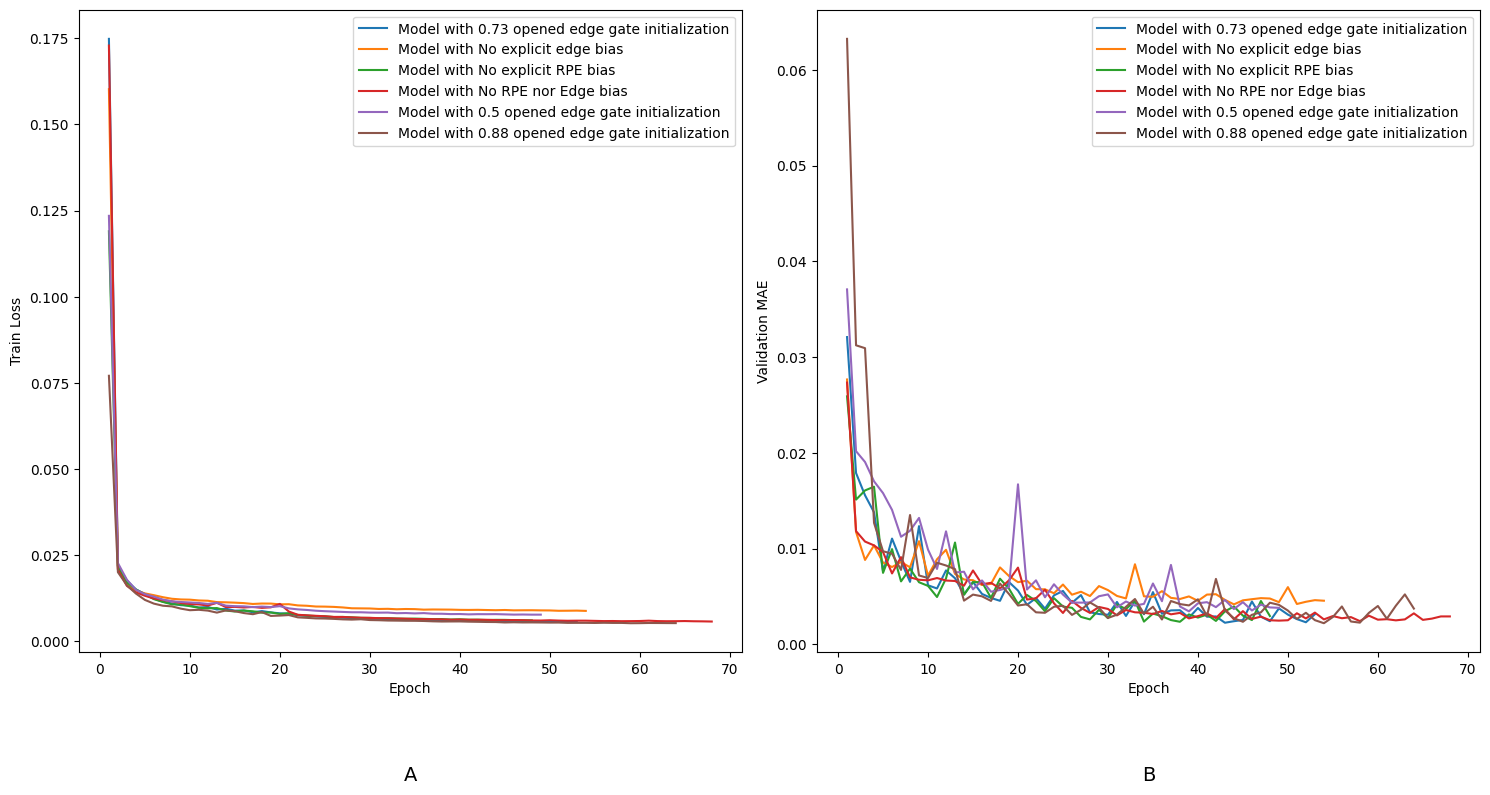

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 8))
axes = axes.flatten()

# Plot for Training Loss Comparison
axes[0].plot(full_model['Epoch'], full_model['Train Loss'], label='Model with 0.73 opened edge gate initialization')
axes[0].plot(edge_ablation['Epoch'], edge_ablation['Train Loss'], label='Model with No explicit edge bias')
axes[0].plot(rpe_ablation['Epoch'], rpe_ablation['Train Loss'], label='Model with No explicit RPE bias')
axes[0].plot(rpe_edge_ablation['Epoch'], rpe_edge_ablation['Train Loss'], label='Model with No RPE nor Edge bias')
axes[0].plot(gate_init_one_ablation['Epoch'], gate_init_one_ablation['Train Loss'], label='Model with 0.5 opened edge gate initialization')
axes[0].plot(gate_init_two_ablation['Epoch'], gate_init_two_ablation['Train Loss'], label='Model with 0.88 opened edge gate initialization')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Train Loss')
axes[0].legend()
axes[0].text(0.5, -0.2, 'A', transform=axes[0].transAxes, fontsize=14, ha='center')

# Plot for Internal Validation MAE Comparison
axes[1].plot(full_model['Epoch'], full_model['Val MAE'], label='Model with 0.73 opened edge gate initialization')
axes[1].plot(edge_ablation['Epoch'], edge_ablation['Val MAE'], label='Model with No explicit edge bias')
axes[1].plot(rpe_ablation['Epoch'], rpe_ablation['Val MAE'], label='Model with No explicit RPE bias')
axes[1].plot(rpe_edge_ablation['Epoch'], rpe_edge_ablation['Val MAE'], label='Model with No RPE nor Edge bias')
axes[1].plot(gate_init_one_ablation['Epoch'], gate_init_one_ablation['Val MAE'], label='Model with 0.5 opened edge gate initialization')
axes[1].plot(gate_init_two_ablation['Epoch'], gate_init_two_ablation['Val MAE'], label='Model with 0.88 opened edge gate initialization')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Validation MAE')
axes[1].legend()
axes[1].text(0.5, -0.2, 'B', transform=axes[1].transAxes, fontsize=14, ha='center')


plt.tight_layout()
plt.show()

In [ ]:
# Time taken by each ablation experiment
print("0.73 gate init ablation training time: ", sum(full_model['Epoch Time (min)']), "minutes")
print("0.50 gate init ablation training time: ", sum(gate_init_one_ablation['Epoch Time (min)']), "minutes")
print("0.88 gate init ablation training time: ", sum(gate_init_two_ablation['Epoch Time (min)']), "minutes")
print("rpe ablation training time: ", sum(rpe_ablation['Epoch Time (min)']), "minutes")
print("edge ablation training time: ", sum(edge_ablation['Epoch Time (min)']), "minutes")
print("rpe_edge ablation training time: ", sum(rpe_edge_ablation['Epoch Time (min)']), "minutes")

0.73 gate init ablation training time:  16.39 minutes
0.50 gate init ablation training time:  14.989999999999998 minutes
0.88 gate init ablation training time:  20.45 minutes
rpe ablation training time:  15.030000000000001 minutes
edge ablation training time:  16.78 minutes
rpe_edge ablation training time:  18.77 minutes


In [ ]:
# then lets assign the time and vae to every ablation experiment

print("0.73 gate init ablation training time =", sum(full_model['Epoch Time (min)']), "minutes", "|| VAE = 0.00225")
print("0.50 gate init ablation training time =", sum(gate_init_one_ablation['Epoch Time (min)']), "minutes", "|| VAE = 0.00344")
print("0.88 gate init ablation training time: ", sum(gate_init_two_ablation['Epoch Time (min)']), "minutes", "|| VAE = 0.00220")
print("rpe ablation training time: ", sum(rpe_ablation['Epoch Time (min)']), "minutes", "|| VAE = 0.00235")
print("edge ablation training time: ", sum(edge_ablation['Epoch Time (min)']), "minutes", "|| VAE = 0.00417")
print("rpe_edge ablation training time: ", sum(rpe_edge_ablation['Epoch Time (min)']), "minutes", "|| VAE = 0.00242")

0.73 gate init ablation training time = 16.39 minutes || VAE = 0.00225
0.50 gate init ablation training time = 14.989999999999998 minutes || VAE = 0.00344
0.88 gate init ablation training time:  20.45 minutes || VAE = 0.00220
rpe ablation training time:  15.030000000000001 minutes || VAE = 0.00235
edge ablation training time:  16.78 minutes || VAE = 0.00417
rpe_edge ablation training time:  18.77 minutes || VAE = 0.00242


In [ ]:
# TOOK THESE TIMES TO ACHIEVE THESE VAE AT EARLY STOPPING PATIENCE OF 10.

In [ ]:
# then compute the convergence efficiencies
time_gate_073 = sum(full_model['Epoch Time (min)'])
time_gate_050 = sum(gate_init_one_ablation['Epoch Time (min)'])
time_gate_088 = sum(gate_init_two_ablation['Epoch Time (min)'])
time_rpe = sum(rpe_ablation['Epoch Time (min)'])
time_edge = sum(edge_ablation['Epoch Time (min)'])
time_rpe_edge = sum(rpe_edge_ablation['Epoch Time (min)'])


vae_gate_073 = 0.00225
vae_gate_050 = 0.00344
vae_gate_088 = 0.00220
vae_rpe = 0.00235
vae_edge = 0.00417
vae_rpe_edge = 0.00242


convergence_efficiency_gate_073 = compute_convergence_training_efficiency(time_gate_073, vae_gate_073)
convergence_efficiency_gate_050 = compute_convergence_training_efficiency(time_gate_050, vae_gate_050)
convergence_efficiency_gate_088 = compute_convergence_training_efficiency(time_gate_088, vae_gate_088)
convergence_efficiency_rpe = compute_convergence_training_efficiency(time_rpe, vae_rpe)
convergence_efficiency_edge = compute_convergence_training_efficiency(time_edge, vae_edge)
convergence_efficiency_rpe_edge = compute_convergence_training_efficiency(time_rpe_edge, vae_rpe_edge)


print(f"Convergence Efficiency for Gate 0.73 Ablation Experiment is: {convergence_efficiency_gate_073}")
print(f"Convergence Efficiency for Gate 0.50 Ablation Experiment is: {convergence_efficiency_gate_050}")
print(f"Convergence Efficiency for Gate 0.88 Ablation Experiment is: {convergence_efficiency_gate_088}")
print(f"Convergence Efficiency for RPE Ablation Experiment is: {convergence_efficiency_rpe}")
print(f"Convergence Efficiency for Edge Ablation Experiment is: {convergence_efficiency_edge}")
print(f"Convergence Efficiency for RPE Edge Ablation Experiment is: {convergence_efficiency_rpe_edge}")

Convergence Efficiency for Gate 0.73 Ablation Experiment is: 7284.444444444445
Convergence Efficiency for Gate 0.50 Ablation Experiment is: 4357.558139534884
Convergence Efficiency for Gate 0.88 Ablation Experiment is: 9295.454545454544
Convergence Efficiency for RPE Ablation Experiment is: 6395.744680851064
Convergence Efficiency for Edge Ablation Experiment is: 4023.980815347722
Convergence Efficiency for RPE Edge Ablation Experiment is: 7756.198347107438
